In [3]:
import pandas as pd
import numpy as np


In [4]:
df=pd.read_csv("winequality-red.csv")
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [6]:
df.shape

(1599, 12)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [8]:
df.describe

<bound method NDFrame.describe of       fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0               7.4             0.700         0.00             1.9      0.076   
1               7.8             0.880         0.00             2.6      0.098   
2               7.8             0.760         0.04             2.3      0.092   
3              11.2             0.280         0.56             1.9      0.075   
4               7.4             0.700         0.00             1.9      0.076   
...             ...               ...          ...             ...        ...   
1594            6.2             0.600         0.08             2.0      0.090   
1595            5.9             0.550         0.10             2.2      0.062   
1596            6.3             0.510         0.13             2.3      0.076   
1597            5.9             0.645         0.12             2.0      0.075   
1598            6.0             0.310         0.47             3.6      0.0

In [9]:
df.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

In [10]:
df.dtypes

fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

In [12]:
df['quality'].value_counts(normalize=True).sort_index()*100

quality
3     0.625391
4     3.314572
5    42.589118
6    39.899937
7    12.445278
8     1.125704
Name: proportion, dtype: float64

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns


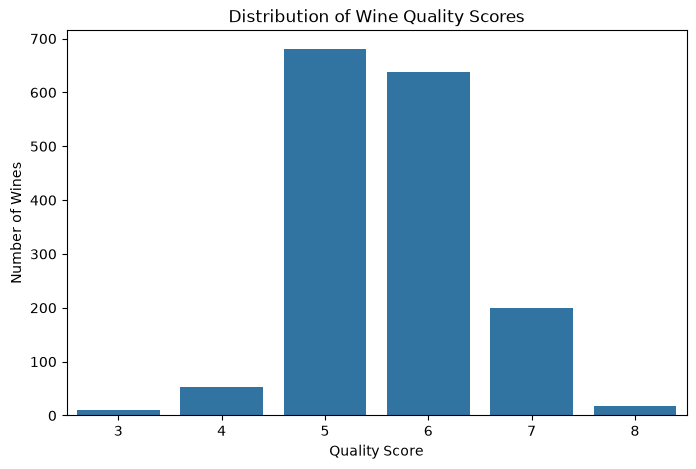

In [16]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='quality')
plt.title('Distribution of Wine Quality Scores')
plt.xlabel('Quality Score')
plt.ylabel('Number of Wines')
plt.show()

In [17]:
chemical_features = df.drop(columns=['quality']).columns

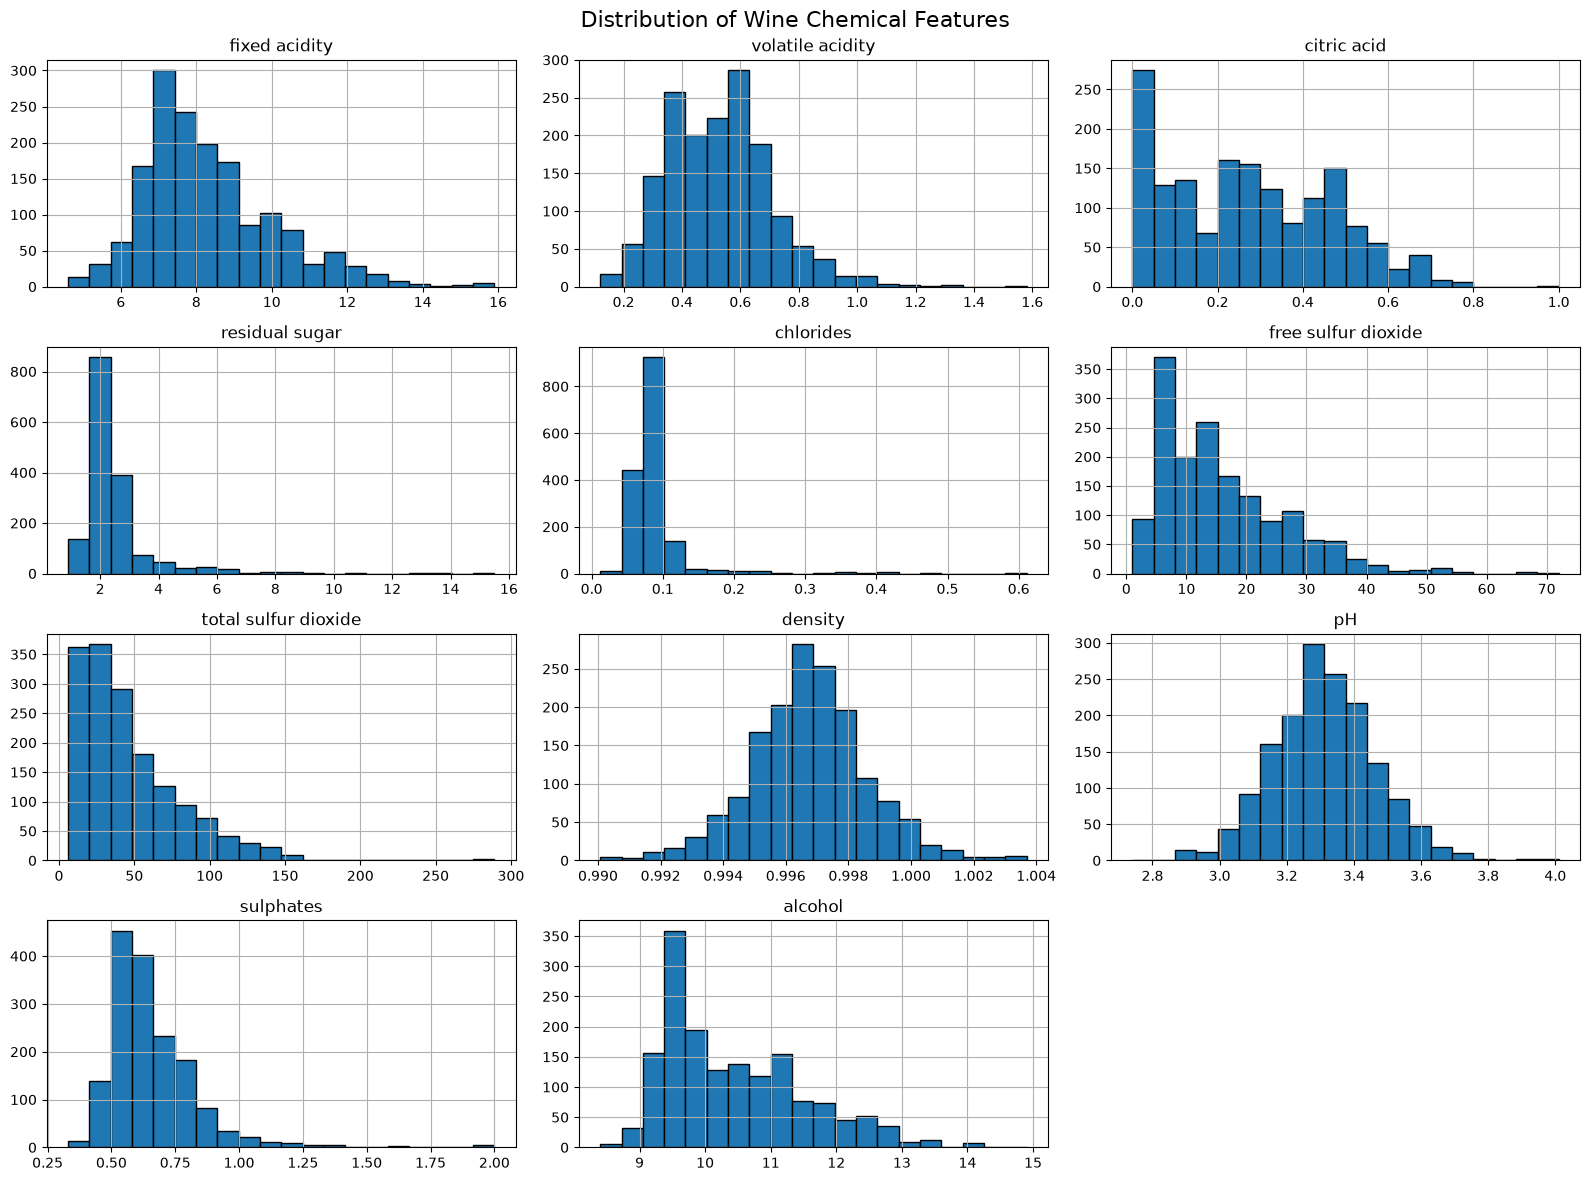

In [20]:
df[chemical_features].hist(
    figsize=(16, 12),
    bins=20,
    edgecolor='black')
plt.suptitle('Distribution of Wine Chemical Features', fontsize=16)
plt.tight_layout()
plt.show()

In [21]:
correlation=df.corr()

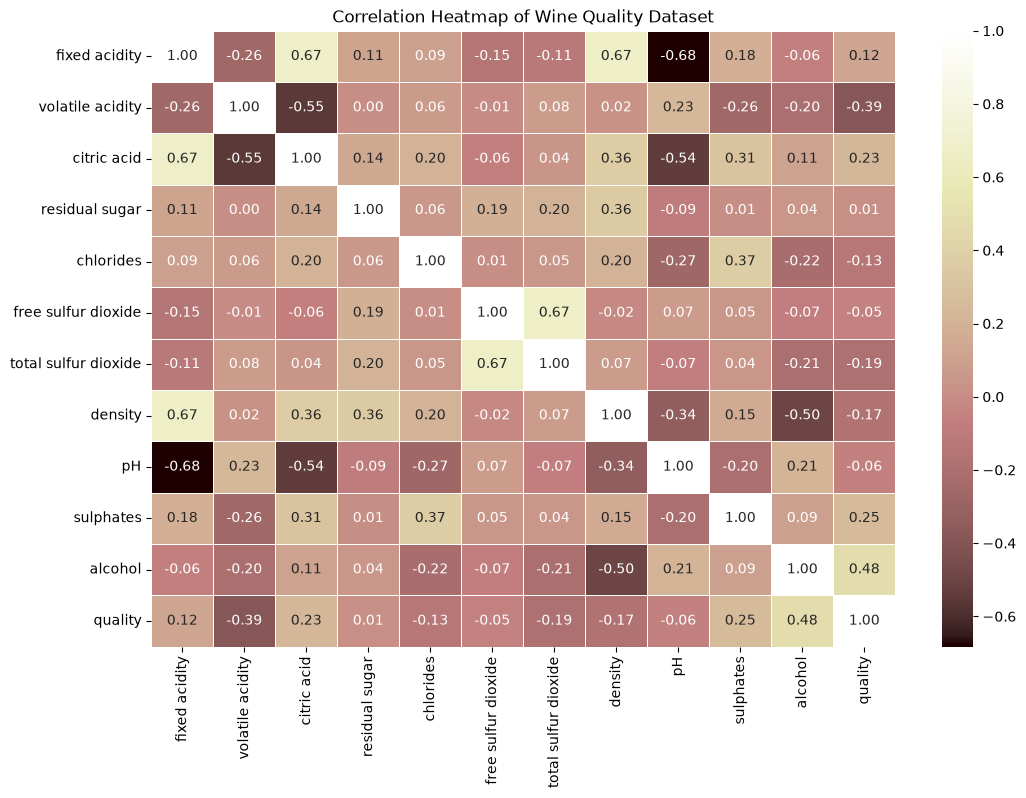

In [22]:
plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation,
    annot=True,
    cmap='pink',
    fmt='.2f',
    linewidths=0.5)
plt.title('Correlation Heatmap of Wine Quality Dataset')
plt.show()

In [23]:
correlation['quality'].sort_values(ascending=False)

quality                 1.000000
alcohol                 0.476166
sulphates               0.251397
citric acid             0.226373
fixed acidity           0.124052
residual sugar          0.013732
free sulfur dioxide    -0.050656
pH                     -0.057731
chlorides              -0.128907
density                -0.174919
total sulfur dioxide   -0.185100
volatile acidity       -0.390558
Name: quality, dtype: float64

In [24]:
quality_counts = df['quality'].value_counts().sort_index()
quality_table = pd.DataFrame({
    'Quality Score': quality_counts.index,
    'Number of Wines': quality_counts.values,
    'Percentage': (quality_counts.values / len(df) * 100).round(2)})
print(quality_table)

   Quality Score  Number of Wines  Percentage
0              3               10        0.63
1              4               53        3.31
2              5              681       42.59
3              6              638       39.90
4              7              199       12.45
5              8               18        1.13


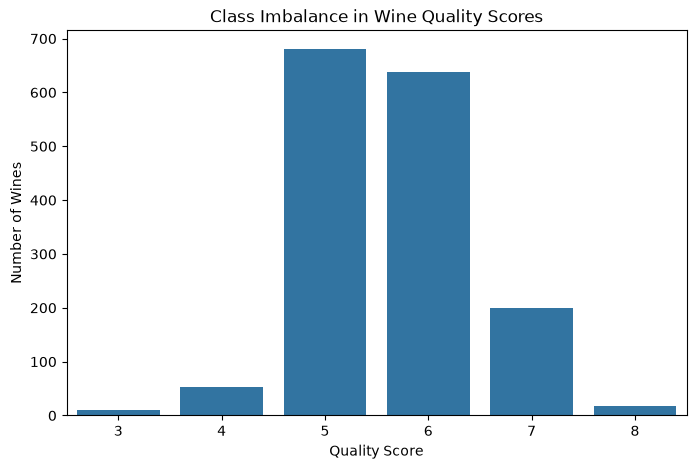

In [25]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='quality')
plt.title('Class Imbalance in Wine Quality Scores')
plt.xlabel('Quality Score')
plt.ylabel('Number of Wines')
plt.show()

In [26]:
df_model = df.copy()
def quality_category(score):
    if score <= 4:
        return 'Low'
    elif score <= 6:
        return 'Medium'
    else:
        return 'High'
df_model['quality_category'] = df_model['quality'].apply(quality_category)
df_model[['quality', 'quality_category']].head()

,quality,quality_category
0,5,Medium
1,5,Medium
2,5,Medium
3,6,Medium
4,5,Medium


In [27]:
df_model['quality_category'].value_counts()

quality_category
Medium    1319
High       217
Low         63
Name: count, dtype: int64

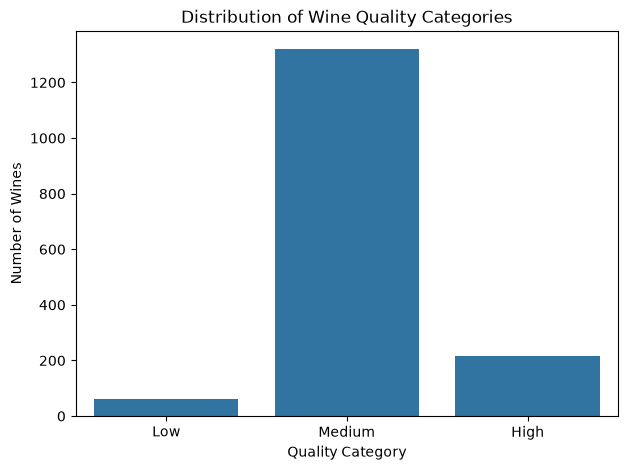

In [28]:
plt.figure(figsize=(7,5))
sns.countplot(
    data=df_model,
    x='quality_category',
    order=['Low', 'Medium', 'High'])
plt.title('Distribution of Wine Quality Categories')
plt.xlabel('Quality Category')
plt.ylabel('Number of Wines')
plt.show()

In [29]:
X = df_model.drop(columns=['quality', 'quality_category'])
y = df_model['quality_category']
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1599, 11)
Target shape: (1599,)


In [30]:
from sklearn.model_selection import train_test_split

In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1279, 11)
Testing data: (320, 11)


In [32]:
print("Original class distribution:")
print(y.value_counts(normalize=True).round(3))
print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).round(3))
print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True).round(3))

Original class distribution:
quality_category
Medium    0.825
High      0.136
Low       0.039
Name: proportion, dtype: float64

Training class distribution:
quality_category
Medium    0.825
High      0.136
Low       0.039
Name: proportion, dtype: float64

Testing class distribution:
quality_category
Medium    0.825
High      0.134
Low       0.041
Name: proportion, dtype: float64


In [33]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

In [34]:
#Model1:Random Forest Classifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced')
rf_model.fit(X_train, y_train)
print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [35]:
#Model 2: Stochastic Gradient Descent (SGD) Classifier
sgd_model = make_pipeline(
    StandardScaler(),
    SGDClassifier(
        max_iter=1000,
        random_state=42,
        class_weight='balanced'
    )
)
sgd_model.fit(X_train, y_train)
print("SGD Classifier trained successfully!")

SGD Classifier trained successfully!


In [36]:
#Model 3: Support Vector Classifier (SVC)
svc_model = make_pipeline(
    StandardScaler(),
    SVC(
        kernel='rbf',
        class_weight='balanced',
        random_state=42
    )
)

svc_model.fit(X_train, y_train)

print("SVC model trained successfully!")

SVC model trained successfully!


In [37]:
models = {
    'Random Forest': rf_model,
    'SGD Classifier': sgd_model,
    'SVC': svc_model
}

for name, model in models.items():
    print(name, "is ready for prediction")

Random Forest is ready for prediction
SGD Classifier is ready for prediction
SVC is ready for prediction


In [38]:
from sklearn.metrics import (accuracy_score, classification_report,confusion_matrix,ConfusionMatrixDisplay,precision_score,recall_score,f1_score)

In [39]:
rf_pred = rf_model.predict(X_test)
sgd_pred = sgd_model.predict(X_test)
svc_pred = svc_model.predict(X_test)

In [40]:
print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_pred))
print(classification_report(y_test, rf_pred))

Random Forest Accuracy: 0.8375
              precision    recall  f1-score   support

        High       0.55      0.74      0.63        43
         Low       0.25      0.08      0.12        13
      Medium       0.91      0.89      0.90       264

    accuracy                           0.84       320
   macro avg       0.57      0.57      0.55       320
weighted avg       0.84      0.84      0.83       320



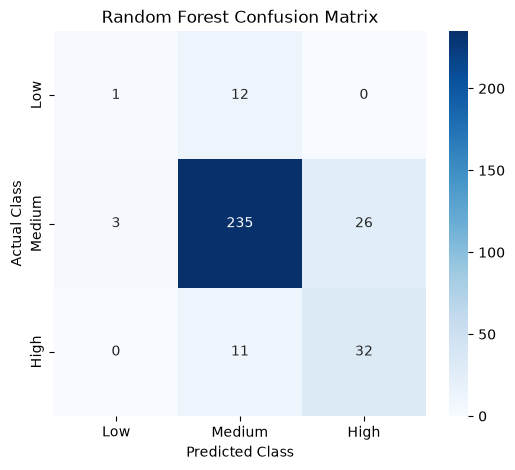

In [41]:
cm_rf = confusion_matrix(
    y_test, rf_pred,
    labels=['Low', 'Medium', 'High']
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Low', 'Medium', 'High'],
    yticklabels=['Low', 'Medium', 'High']
)

plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.show()

In [42]:
print("SGD Accuracy:",
      accuracy_score(y_test, sgd_pred))
print(classification_report(y_test, sgd_pred))

SGD Accuracy: 0.778125
              precision    recall  f1-score   support

        High       0.49      0.42      0.45        43
         Low       0.09      0.15      0.11        13
      Medium       0.88      0.87      0.87       264

    accuracy                           0.78       320
   macro avg       0.48      0.48      0.48       320
weighted avg       0.79      0.78      0.78       320



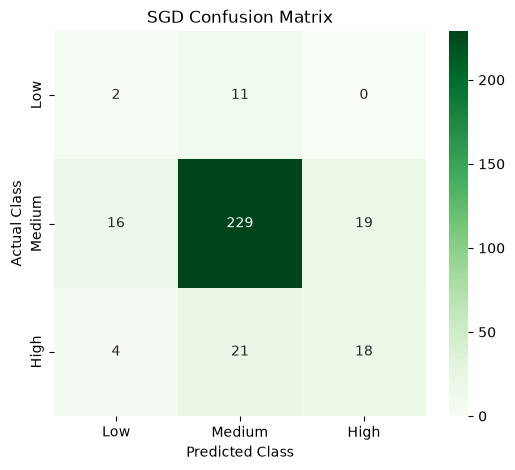

In [43]:
cm_sgd = confusion_matrix(
    y_test, sgd_pred,
    labels=['Low', 'Medium', 'High']
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm_sgd,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Low', 'Medium', 'High'],
    yticklabels=['Low', 'Medium', 'High']
)

plt.title('SGD Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.show()

In [44]:
print("SVC Accuracy:",
      accuracy_score(y_test, svc_pred))
print(classification_report(y_test, svc_pred))

SVC Accuracy: 0.709375
              precision    recall  f1-score   support

        High       0.40      0.74      0.52        43
         Low       0.10      0.23      0.14        13
      Medium       0.92      0.73      0.81       264

    accuracy                           0.71       320
   macro avg       0.47      0.57      0.49       320
weighted avg       0.82      0.71      0.74       320



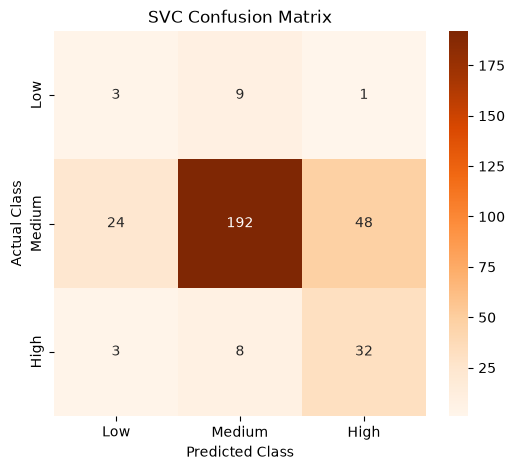

In [45]:
cm_svc = confusion_matrix(
    y_test, svc_pred,
    labels=['Low', 'Medium', 'High']
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm_svc,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=['Low', 'Medium', 'High'],
    yticklabels=['Low', 'Medium', 'High']
)

plt.title('SVC Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.show()

In [46]:
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance

,Feature,Importance
1,volatile acidity,0.152703
9,sulphates,0.139616
10,alcohol,0.137513
2,citric acid,0.101354
6,total sulfur dioxide,0.078922
8,pH,0.073782
4,chlorides,0.071609
7,density,0.064867
0,fixed acidity,0.064488
5,free sulfur dioxide,0.061612


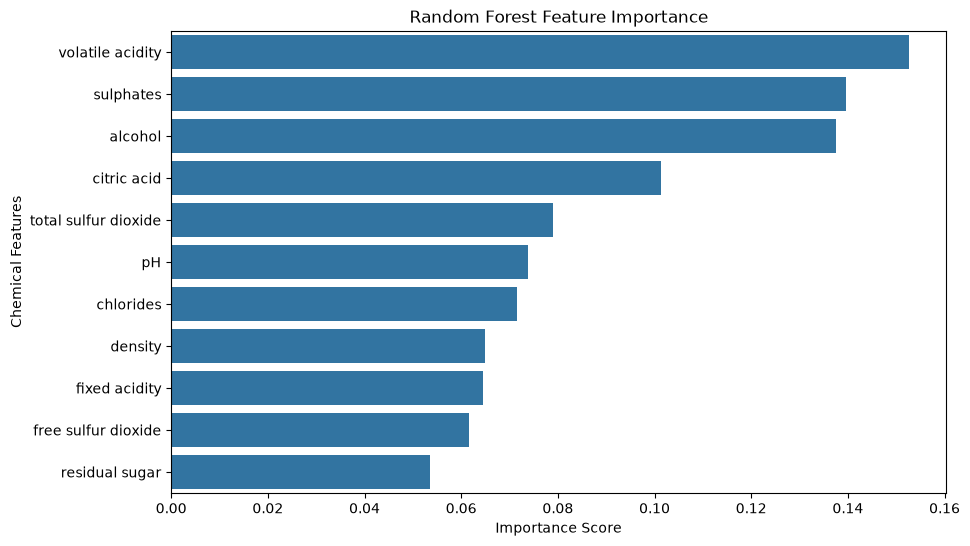

In [47]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Random Forest Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Chemical Features')

plt.show()

In [48]:
model_results = []

predictions = {
    'Random Forest': rf_pred,
    'SGD Classifier': sgd_pred,
    'SVC': svc_pred
}

for name, pred in predictions.items():

    model_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(
            y_test, pred, average='macro', zero_division=0
        ),
        'Recall': recall_score(
            y_test, pred, average='macro', zero_division=0
        ),
        'F1 Score': f1_score(
            y_test, pred, average='macro', zero_division=0
        )
    })

comparison_df = pd.DataFrame(model_results)

comparison_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.8375,0.5709,0.5704,0.5506
1,SGD Classifier,0.7781,0.4849,0.4800,0.4789
2,SVC,0.7094,0.4712,0.5674,0.4892


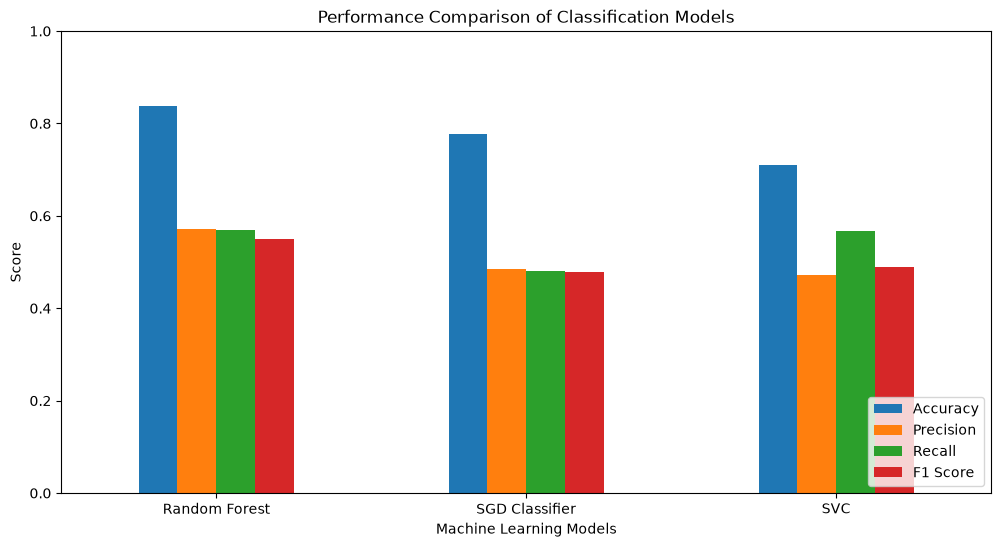

In [49]:
comparison_df.set_index('Model')[
    ['Accuracy', 'Precision', 'Recall', 'F1 Score']
].plot(
    kind='bar',
    figsize=(12,6)
)

plt.title('Performance Comparison of Classification Models')
plt.ylabel('Score')
plt.xlabel('Machine Learning Models')
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.show()

In [50]:
best_model = comparison_df.loc[
    comparison_df['F1 Score'].idxmax()
]
print("Best Model:", best_model['Model'])
print("Accuracy:", round(best_model['Accuracy'], 4))
print("Macro F1 Score:", round(best_model['F1 Score'], 4))

Best Model: Random Forest
Accuracy: 0.8375
Macro F1 Score: 0.5506


Random Forest is a strong candidate for deployment because it can capture complex relationships, handles different feature patterns, and provides feature importance scores. However, the final model should be selected based on the actual evaluation results. If SGD or SVC achieves a better macro F1-score and performs more consistently across minority classes, it may be a better choice.